# Livrable 1 - Classification binaire

## Introduction
L'entreprise voulant automatiser la sélection de photos pour l'annotations, le livrable 2 devra fournir une méthode de classification se basant sur les réseaux de neurones afin de filtrer les images qui ne sont pas des photos du dataset de départ. La solution pourra s'appuyer sur l'architecture de réseau de neurones de votre choix, que vous justifierez notamment du point de vue des résultats obtenus.

## Description du livrable

Le livrable sera sous la forme notebook Jupyter et devra, pour être validé, intégrer :

1. Le code TensorFlow ainsi qu'un schéma de l'architecture du réseau de neurones. Toutes les parties doivent être détaillée dans le notebook : les paramètres du réseau, la fonction de perte ainsi que l'algorithme d'optimisation utilisé pour l’entraînement.

2. Un graphique contenant l'évolution de l'erreur d’entraînement ainsi que de l'erreur de test et l'évolution de l'accuracy pour ces deux datasets.

3. L'analyse de ces résultats, notamment le compromis entre biais et variance (ou sur-apprentissage et sous-apprentissage).

4. Une description des méthodes potentiellement utilisables pour améliorer les compromis biais/variance : technique de régularisation, drop out, early-stopping, ...

Plusieurs dataset sont à votre disposition. On a :

- Des peintures
- Des Schéma et graphes
- Des portraits dessinés en noir et blanc
- Des images de textes scannés
- Des photos

structure du CNN :

- importation du dataset avec x train x label
- Normalisation des données /255
- Convulation (conv2d) avec kernel et pooling (Maxpooling2D)
- Ensuite Flatten
- ensuite Dense
- Ensuite sigmoid 

# Importation des librairies

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from keras import layers, models
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1


## Importation du Dataset

In [3]:
IMG_SIZE = 64  
BATCH_SIZE = 32
dataset_dir = str(IMG_SIZE)

# 1. Chargement des 75% pour l'entraînement (on met 25% de côté)
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.25, 
    subset="training",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# 2. Chargement des 25% restants (Val + Test)
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.25,
    subset="validation",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# 3. Découpage des 25% restants : 60% pour la Val (soit 15% du total) et 40% pour le Test (soit 10% du total)
val_test_batches = tf.data.experimental.cardinality(val_test_ds)
test_batches = (val_test_batches * 6) // 10  # On calcule 60% des batchs

test_ds = val_test_ds.take(test_batches)
val_ds = val_test_ds.skip(test_batches)

print(f"\nRépartition des batchs :")
print(f"Train (75%) : {tf.data.experimental.cardinality(train_ds).numpy()} batchs")
print(f"Validation (10%) : {tf.data.experimental.cardinality(val_ds).numpy()} batchs")
print(f"Test (15%) : {tf.data.experimental.cardinality(test_ds).numpy()} batchs")

Found 62812 files belonging to 2 classes.
Using 47109 files for training.
Found 62812 files belonging to 2 classes.
Using 15703 files for validation.

Répartition des batchs :
Train (75%) : 1473 batchs
Validation (10%) : 197 batchs
Test (15%) : 294 batchs


## Initialisation du model

In [5]:
model = models.Sequential()
model.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
model.add(layers.Rescaling(1./255))

model.add(layers.Conv2D(32,(3,3), activation='relu'))
model.add(layers.MaxPool2D((2,2)))

model.add(layers.Conv2D(64,(3,3), activation='relu'))
model.add(layers.MaxPool2D((2,2)))

model.add(layers.Conv2D(128,(3,3), activation='relu'))
model.add(layers.MaxPool2D((2,2)))

model.add(layers.Flatten())

model.add(layers.Dense(128, activation='relu'))

model.add(layers.Dropout(0.5))

model.add(layers.Dense(1, activation='sigmoid'))


## Compilation du modèle

In [6]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history= model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


c:\Users\chris\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1473/1473 ━━━━━━━━━━━━━━━━━━━━ 98s 65ms/step - accuracy: 0.8568 - loss: 0.3002 - val_accuracy: 0.9037 - val_loss: 0.2060
Epoch 2/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 52s 35ms/step - accuracy: 0.9029 - loss: 0.2137 - val_accuracy: 0.9163 - val_loss: 0.1926
Epoch 3/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 53s 36ms/step - accuracy: 0.9141 - loss: 0.1923 - val_accuracy: 0.9180 - val_loss: 0.1847
Epoch 4/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 55s 37ms/step - accuracy: 0.9247 - loss: 0.1729 - val_accuracy: 0.9263 - val_loss: 0.1721
Epoch 5/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 56s 38ms/step - accuracy: 0.9312 - loss: 0.1578 - val_accuracy: 0.9255 - val_loss: 0.1676
Epoch 6/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 320s 217ms/step - accuracy: 0.9390 - loss: 0.1417 - val_accuracy: 0.9263 - val_loss: 0.1706
Epoch 7/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 51s 34ms/step - accuracy: 0.9450 - loss: 0.1305 - val_accuracy: 0.9268 - val_loss: 0.1753
Epoch 8/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 54s 37ms/step - accuracy: 0.9513 - loss: 0.

## Analyse par graphique


-> Évaluation sur le set de Test (64x64) :
294/294 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9304 - loss: 0.1984

-> Graphique sauvegardé sous : courbes_64.png


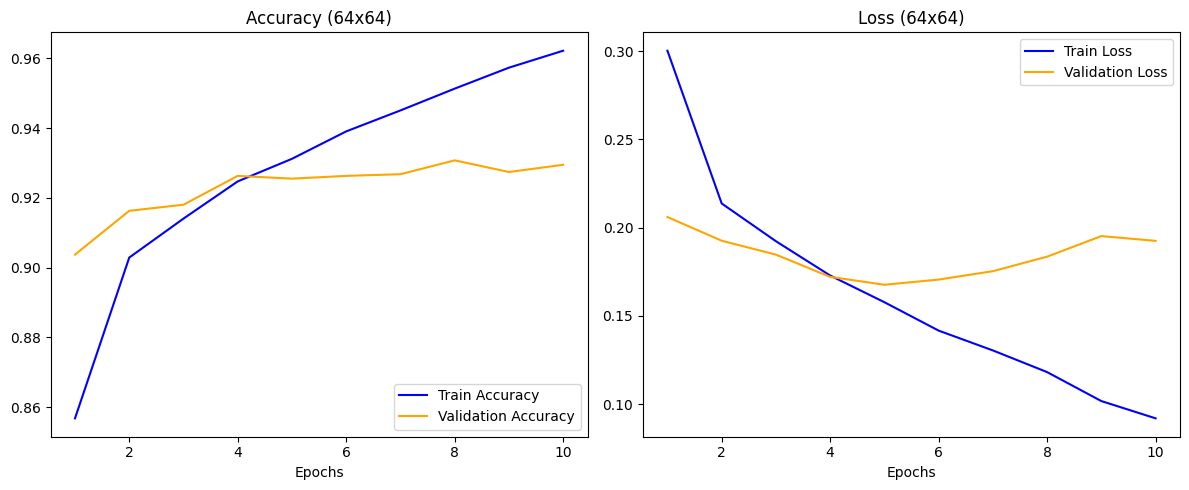

In [ ]:

print(f"\n-> Évaluation sur le set de Test ({IMG_SIZE}x{IMG_SIZE}) :")
test_loss, test_acc = model.evaluate(test_ds)


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)


plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Train Accuracy', color='blue')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange')
plt.title(f'Accuracy ({IMG_SIZE}x{IMG_SIZE})')
plt.xlabel('Epochs')
plt.legend(loc='lower right')


plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Train Loss', color='blue')
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange')
plt.title(f'Loss ({IMG_SIZE}x{IMG_SIZE})')
plt.xlabel('Epochs')
plt.legend(loc='upper right')

plt.tight_layout()


filename = f"courbes_{IMG_SIZE}.png"
plt.savefig(filename)
print(f"\n-> Graphique sauvegardé sous : {filename}")


plt.show()